# 04 - Comparing Explanations Across Groups (RQ2, RQ3, RQ4)

Phase 3 showed the models' *predictions* are unequal. This notebook asks whether the *explanations* differ too.

**RQ2.** Do SHAP and LIME explanations differ between demographic groups?
| Measure | Meaning |
|---|---|
| Sensitive reliance | per person: share of total absolute attribution given to the sensitive feature (e.g. `sex`) |
| Proxy reliance | the same share for the 3 features most associated with the sensitive attribute (mutual information) |
| Global importance | mean absolute attribution per feature within each group |
| Rank agreement | Spearman rho / Kendall tau between the groups' rankings (1 = identical), top-5 Jaccard, bootstrap 95% CI |
| Fidelity gap (LIME) | difference in mean local R-squared of LIME's surrogate between groups |

**RQ3.** Are the differences statistically significant? Mann-Whitney U per measure, Holm-corrected.
* H0: the measure has the same distribution in both groups.
* H1: the distributions differ.

**RQ4.** Which model + XAI method balances accuracy, fairness and explanation consistency best? (Pareto analysis)

In [1]:
# --- Setup: works both in Google Colab and locally ---------------------------
# Colab: choose ONE way to get the project:
#   (a) USE_DRIVE = True  -> upload the fairness-xai folder to "My Drive"
#   (b) REPO_URL = "..."  -> clone it from GitHub
# Locally (Jupyter / VS Code) nothing needs changing.
import importlib.metadata
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
USE_DRIVE = False
DRIVE_PROJECT = "/content/drive/MyDrive/fairness-xai"
REPO_URL = ""  # e.g. "https://github.com/<your-user>/fairness-xai.git"

if IN_COLAB:
    if USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_ROOT = Path(DRIVE_PROJECT)
    elif REPO_URL:
        PROJECT_ROOT = Path("/content/fairness-xai")
        if not PROJECT_ROOT.exists():
            subprocess.run(["git", "clone", REPO_URL, str(PROJECT_ROOT)], check=True)
    else:
        raise RuntimeError("Set USE_DRIVE = True or REPO_URL so Colab can find the project.")
    # Install the pinned versions once. If Colab then asks to "Restart session",
    # click it and run this cell again - the install is skipped the second time.
    try:
        already = importlib.metadata.version("shap") == "0.48.0"
    except importlib.metadata.PackageNotFoundError:
        already = False
    if not already:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                        str(PROJECT_ROOT / "requirements.txt")], check=True)
else:
    # Locally the notebook runs from notebooks/, so the project root is its parent.
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: C:\Users\tarun\Desktop\Mini Project\fairness-xai


In [2]:
%matplotlib inline
import pandas as pd
from IPython.display import display

from src import config
from src.compare import (build_tradeoff, interpret_comparison, plot_fidelity_boxes, plot_reliance_boxes,
                         plot_top_features, run_comparison, save_comparison_tables, save_tradeoff)
from src.explain import QUICK_SETTINGS, ExplainSettings, run_explanations, tidy_explanations
from src.models import load_model, model_path, train_all
from src.preprocess import prepare_dataset
from src.stats import run_stat_tests, save_stat_tests

config.setup_logging()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# QUICK = True uses tiny samples (a few minutes on Colab) and writes to results/quick/.
# QUICK = False uses the full samples; if `python -m src.run_all` already ran, the cached
# explanations are reused and this notebook takes about a minute.
QUICK = False
if QUICK:
    config.set_results_dir(config.PROJECT_ROOT / "results" / "quick")
SETTINGS, N_BOOT = (QUICK_SETTINGS, config.QUICK_N_BOOTSTRAP) if QUICK else (ExplainSettings(), config.N_BOOTSTRAP)
print("Explanation sample:", SETTINGS, "| bootstrap resamples:", N_BOOT)

Explanation sample: ExplainSettings(shap_n_per_group=200, lime_n_per_group=100, lime_num_samples=1000, seed=42) | bootstrap resamples: 1000


C:\Users\tarun\Desktop\Mini Project\fairness-xai\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Explain and compare
For each dataset: load the models, explain the same sampled test instances with SHAP and LIME (cached in
`results/cache/`), then compute every comparison measure.

In [3]:
prepared, explanations, parts = {}, {}, {}
for name in config.DATASETS:
    loaded, split = prepare_dataset(name, save=False)
    if all(model_path(name, s, m).exists() for s in config.SETTINGS for m in config.MODEL_NAMES):
        fitted = {(s, m): load_model(name, s, m) for s in config.SETTINGS for m in config.MODEL_NAMES}
    else:
        fitted = train_all(split, loaded.metadata)
    instances, tables = run_explanations(name, fitted, split, loaded.metadata, SETTINGS)
    prepared[name] = (loaded, split)
    explanations[name] = (instances, tables)
    # Figures were written by run_all; here we draw selected ones inline instead.
    parts[name] = run_comparison(split, loaded.metadata, instances, tables, N_BOOT, save_figures=False)

results = {key: pd.concat([p[key] for p in parts.values()], ignore_index=True) for key in parts["adult"]}
save_comparison_tables(results)
comparison, per_instance, importance = results["comparison"], results["per_instance"], results["importance"]
print(f"{len(comparison)} comparisons, {len(per_instance)} per-instance rows")

22:28:12 | INFO    | src.data | Loaded Adult from OpenML via fairlearn (48842 rows).


22:28:12 | INFO    | src.data | Adult ready: 45222 rows, 12 features, positive rate 0.248.


22:28:13 | INFO    | src.explain | Using cached explanations explanations_adult_with_sensitive_logistic_regression_s200_l100_n1000.csv


22:28:13 | INFO    | src.explain | Using cached explanations explanations_adult_with_sensitive_random_forest_s200_l100_n1000.csv


22:28:13 | INFO    | src.explain | Using cached explanations explanations_adult_with_sensitive_xgboost_s200_l100_n1000.csv


22:28:13 | INFO    | src.explain | Using cached explanations explanations_adult_without_sensitive_logistic_regression_s200_l100_n1000.csv


... (14 outputs left out)

22:28:46 | INFO    | src.compare | Wrote per_instance_reliance.csv (14400 rows).


22:28:46 | INFO    | src.compare | Wrote global_importance.csv (864 rows).


22:28:46 | INFO    | src.compare | Wrote proxies.csv (32 rows).


48 comparisons, 14400 per-instance rows


### The tidy explanation table
One row per instance x method x original feature; attributions are absolute values summed over one-hot columns.

In [4]:
instances, tables = explanations["adult"]
tidy = tidy_explanations(tables[("with_sensitive", "xgboost")], instances, "sex")
display(tidy.head(8))
print(tidy.groupby(["method", "group"])["instance_id"].nunique().rename("instances").to_frame())

,instance_id,group,method,original_feature,attribution
0,120,Male,shap,age,0.437802
1,137,Male,shap,age,0.774753
2,241,Female,shap,age,0.346745
3,363,Female,shap,age,1.415582
4,420,Female,shap,age,1.475965
5,449,Male,shap,age,4.353229
6,462,Male,shap,age,0.075239
7,602,Male,shap,age,0.608279


               instances
method group            
lime   Female        100
       Male          100
shap   Female        200
       Male          200


## 2. Which features are proxies?
Top 3 features by mutual information with each sensitive attribute (training set; sensitive attributes excluded).

In [5]:
proxies = results["proxies"]
display(proxies[proxies["selected"]][["dataset", "attribute", "feature", "mutual_information"]].round(4))

,dataset,attribute,feature,mutual_information
0,adult,sex,relationship,0.2709
1,adult,sex,marital-status,0.1161
2,adult,sex,occupation,0.1033
10,adult,race,native-country,0.0471
11,adult,race,relationship,0.0130
12,adult,race,hours-per-week,0.0086
20,compas,race,age,0.0285
21,compas,race,priors_count,0.0161
22,compas,race,juv_fel_count,0.0110
26,compas,sex,priors_count,0.0119


## 3. Comparison table (RQ2)

In [6]:
cols = ["dataset", "setting", "model", "method", "attribute",
        "sensitive_reliance_privileged", "sensitive_reliance_unprivileged",
        "proxy_reliance_privileged", "proxy_reliance_unprivileged",
        "spearman_rho", "spearman_ci_low", "spearman_ci_high", "kendall_tau", "jaccard_top5",
        "fidelity_privileged", "fidelity_unprivileged", "fidelity_gap"]
display(comparison[cols].round(3))

,dataset,setting,model,method,attribute,sensitive_reliance_privileged,sensitive_reliance_unprivileged,proxy_reliance_privileged,proxy_reliance_unprivileged,spearman_rho,spearman_ci_low,spearman_ci_high,kendall_tau,jaccard_top5,fidelity_privileged,fidelity_unprivileged,fidelity_gap
0,adult,with_sensitive,logistic_regression,shap,sex,0.058,0.125,0.556,0.544,0.937,0.881,0.972,0.848,0.667,NaN,NaN,NaN
1,adult,with_sensitive,logistic_regression,shap,race,0.025,0.146,0.173,0.158,0.713,0.643,0.748,0.667,0.667,NaN,NaN,NaN
2,adult,with_sensitive,logistic_regression,lime,sex,0.022,0.022,0.354,0.353,1.000,0.972,1.000,1.000,1.000,0.751,0.746,0.005
3,adult,with_sensitive,logistic_regression,lime,race,0.023,0.022,0.425,0.429,0.993,0.972,1.000,0.970,1.000,0.753,0.748,0.005
4,adult,with_sensitive,random_forest,shap,sex,0.029,0.056,0.551,0.585,0.979,0.937,0.986,0.909,1.000,NaN,NaN,NaN
5,adult,with_sensitive,random_forest,shap,race,0.004,0.024,0.261,0.266,0.979,0.951,0.993,0.939,1.000,NaN,NaN,NaN
6,adult,with_sensitive,random_forest,lime,sex,0.008,0.008,0.327,0.327,0.993,0.993,1.000,0.970,1.000,0.786,0.786,0.000
7,adult,with_sensitive,random_forest,lime,race,0.006,0.006,0.427,0.434,0.993,0.993,1.000,0.970,1.000,0.788,0.783,0.006
8,adult,with_sensitive,xgboost,shap,sex,0.017,0.063,0.467,0.484,0.958,0.881,0.958,0.909,1.000,NaN,NaN,NaN
9,adult,with_sensitive,xgboost,shap,race,0.004,0.035,0.142,0.144,0.958,0.902,0.965,0.909,1.000,NaN,NaN,NaN


## 4. Top-10 features per group
Left: privileged group, right: unprivileged group. "(sensitive)" and "(proxy)" mark the features of interest.
Shown for each dataset's primary attribute with XGBoost, both methods, with sensitive features.

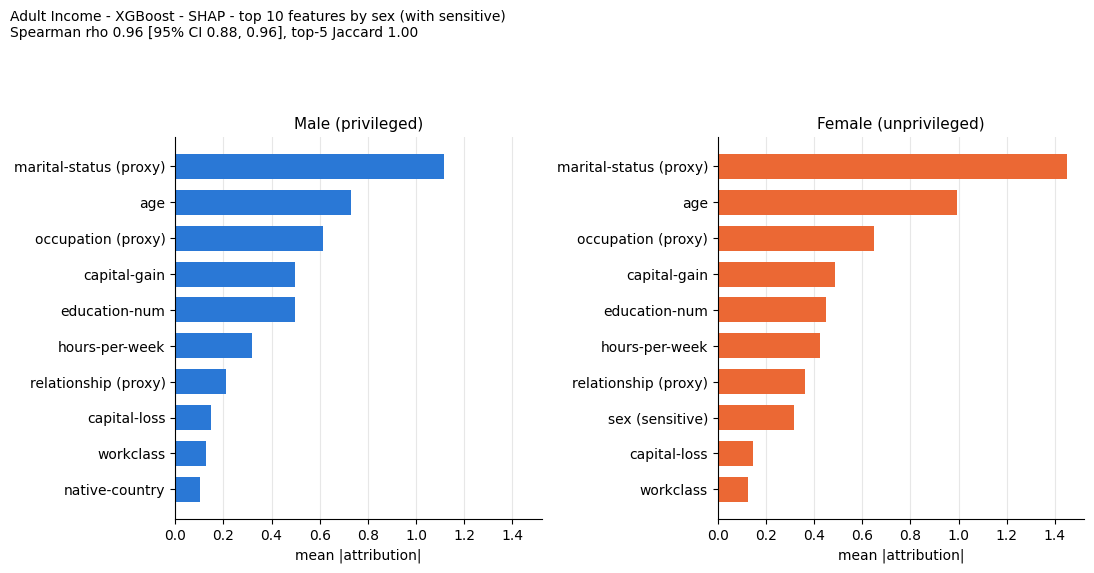

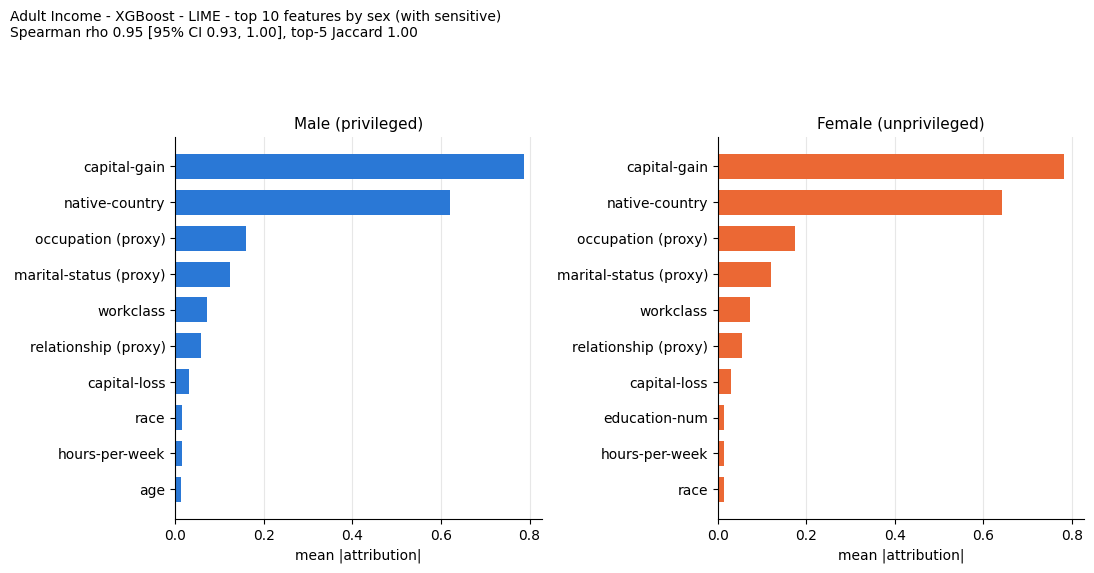

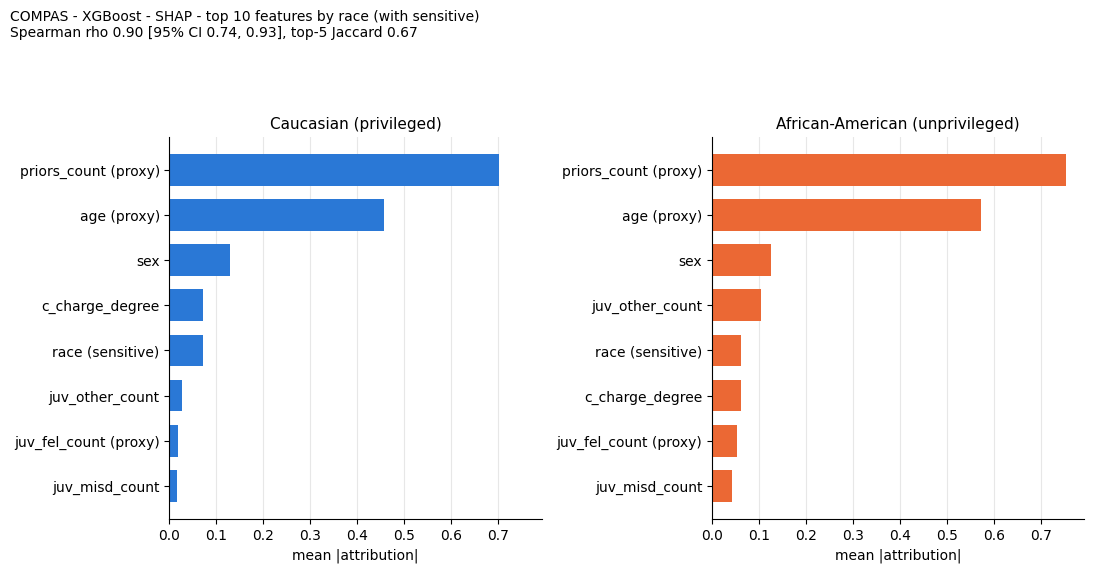

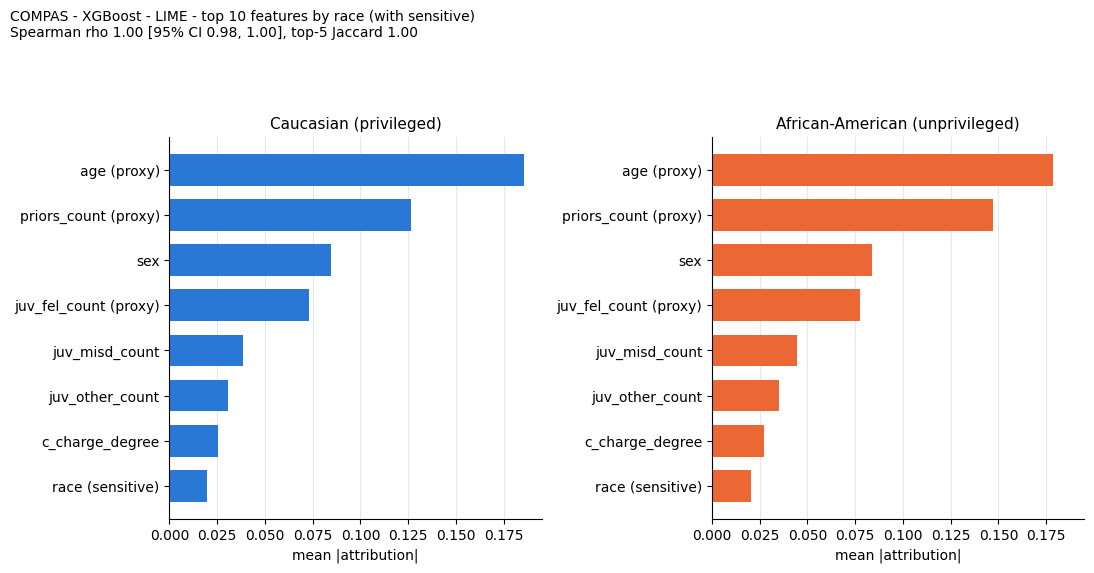

In [7]:
def show(dataset, setting, model, method, attribute):
    row = comparison[(comparison.dataset == dataset) & (comparison.setting == setting) & (comparison.model == model)
                     & (comparison.method == method) & (comparison.attribute == attribute)].iloc[0].to_dict()
    keys = (importance.dataset == dataset) & (importance.setting == setting) & (importance.model == model) \
        & (importance.method == method) & (importance.attribute == attribute)
    display(plot_top_features(importance[keys], row, row["proxies"].split(";")))

for dataset in config.DATASETS:
    attribute = prepared[dataset][0].metadata.primary_sensitive
    for method in config.XAI_METHODS:
        show(dataset, "with_sensitive", "xgboost", method, attribute)

## 5. Reliance and fidelity per group
Box = middle 50% of instances, line = median, circles = outliers.

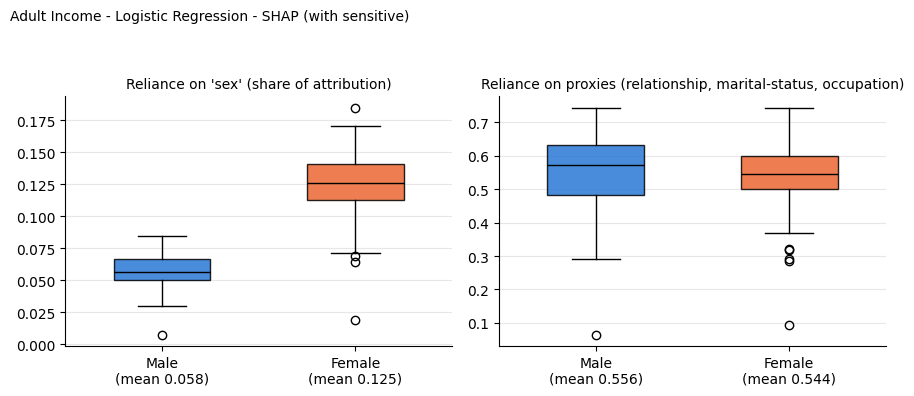

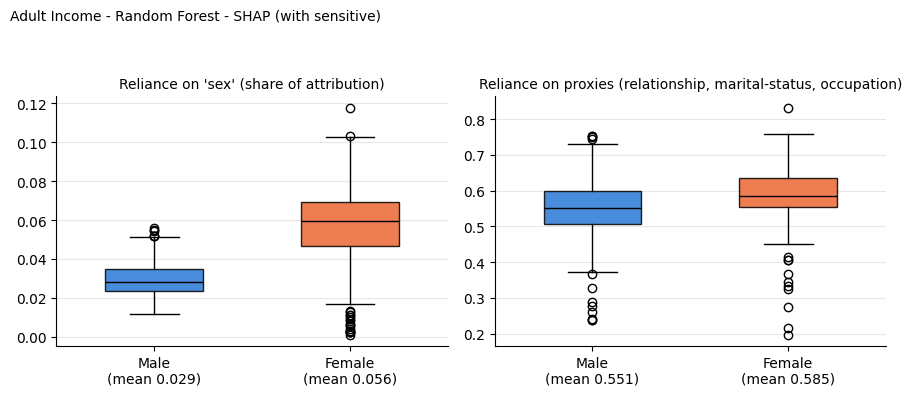

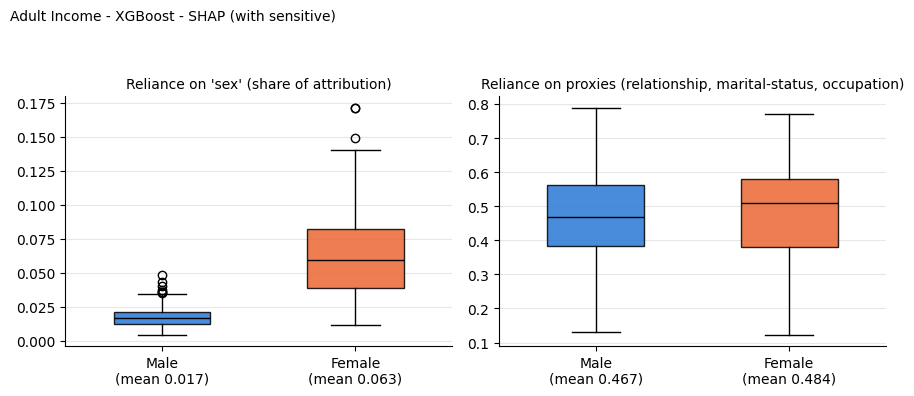

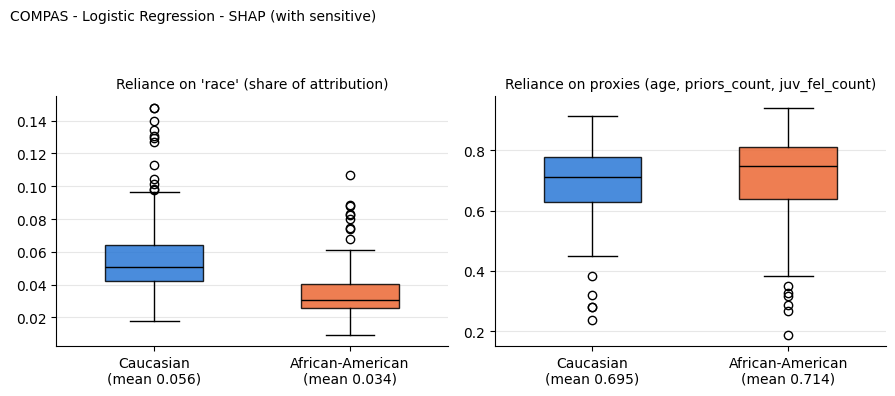

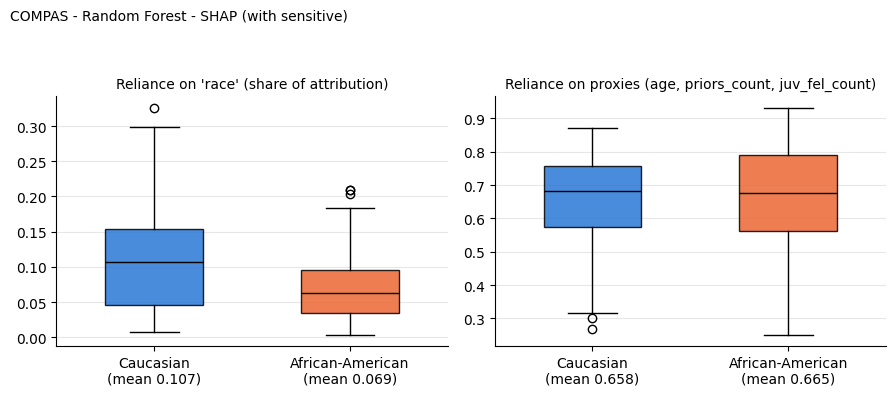

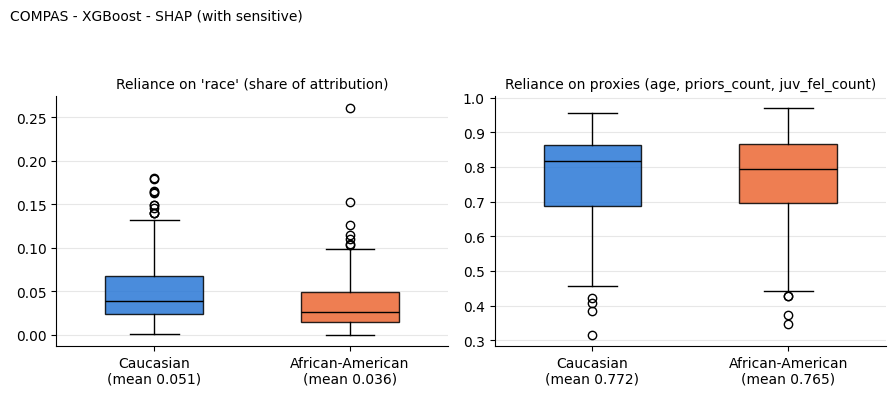

In [8]:
for dataset in config.DATASETS:
    attribute = prepared[dataset][0].metadata.primary_sensitive
    for model in config.MODEL_NAMES:
        sel = (comparison.dataset == dataset) & (comparison.setting == "with_sensitive") & \
              (comparison.model == model) & (comparison.method == "shap") & (comparison.attribute == attribute)
        row = comparison[sel].iloc[0].to_dict()
        keys = (per_instance.dataset == dataset) & (per_instance.setting == "with_sensitive") & \
               (per_instance.model == model) & (per_instance.method == "shap") & (per_instance.attribute == attribute)
        display(plot_reliance_boxes(per_instance[keys], row))

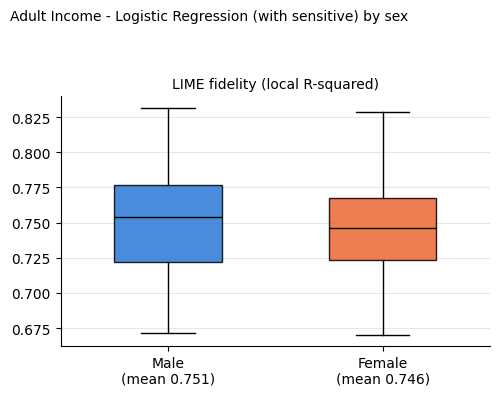

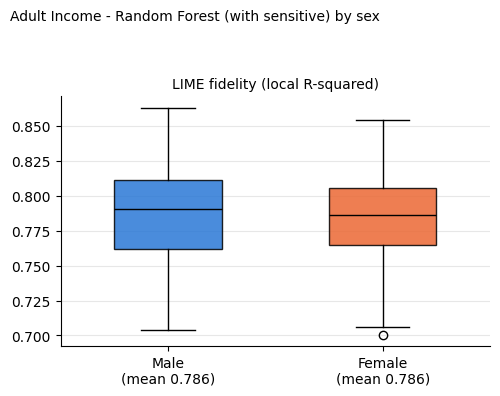

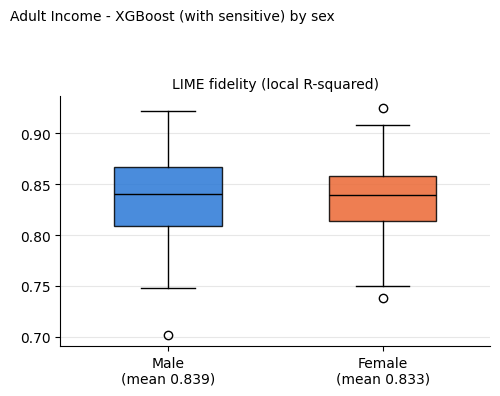

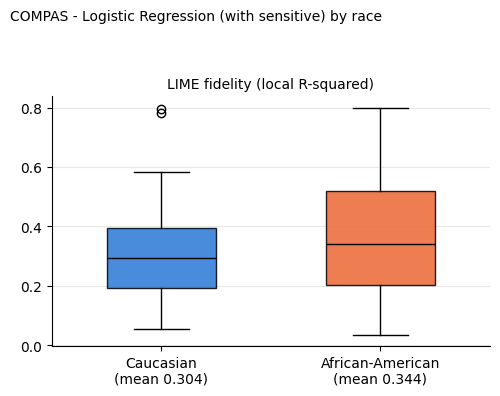

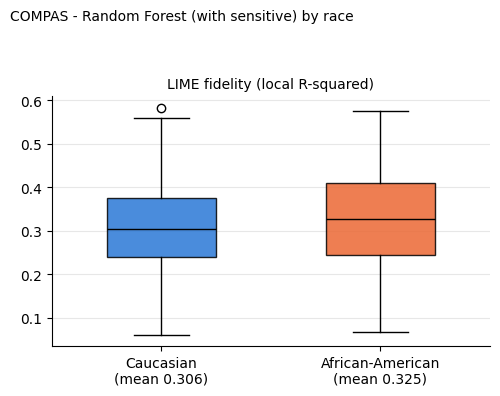

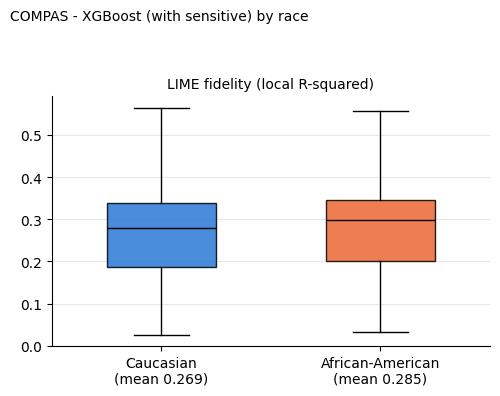

In [9]:
for dataset in config.DATASETS:
    attribute = prepared[dataset][0].metadata.primary_sensitive
    for model in config.MODEL_NAMES:
        sel = (comparison.dataset == dataset) & (comparison.setting == "with_sensitive") & \
              (comparison.model == model) & (comparison.method == "lime") & (comparison.attribute == attribute)
        keys = (per_instance.dataset == dataset) & (per_instance.setting == "with_sensitive") & \
               (per_instance.model == model) & (per_instance.method == "lime") & (per_instance.attribute == attribute)
        display(plot_fidelity_boxes(per_instance[keys], comparison[sel].iloc[0].to_dict()))

## 6. Statistical tests (RQ3)
Mann-Whitney U per comparison and measure; Holm correction across **all** tests of this run.
`rank_biserial` > 0 means the privileged group tends to have larger values.

In [10]:
tests = run_stat_tests(per_instance)
save_stat_tests(tests)
summary = tests.groupby("measure").agg(tests=("p_value", "size"),
                                       significant_raw=("significant_raw", "sum"),
                                       significant_holm=("significant_holm", "sum"))
display(summary)
display(tests[tests["significant_holm"]][
    ["dataset", "setting", "model", "method", "attribute", "measure", "mean_privileged", "mean_unprivileged",
     "p_value", "p_holm", "rank_biserial"]].sort_values("p_holm").round(4))

22:28:49 | INFO    | src.stats | 96 tests: 21 significant before and 17 after Holm correction (alpha 0.05).


22:28:49 | INFO    | src.stats | Wrote stat_tests.csv (96 rows).


,tests,significant_raw,significant_holm
measure,,,
fidelity,24,0,0
proxy_reliance,48,9,5
sensitive_reliance,24,12,12


,dataset,setting,model,method,attribute,measure,mean_privileged,mean_unprivileged,p_value,p_holm,rank_biserial
2,adult,with_sensitive,logistic_regression,shap,race,sensitive_reliance,0.0252,0.1461,0.0,0.0000,-1.0000
50,compas,with_sensitive,logistic_regression,shap,sex,sensitive_reliance,0.2329,0.0554,0.0,0.0000,0.9965
22,adult,with_sensitive,xgboost,shap,race,sensitive_reliance,0.0042,0.0345,0.0,0.0000,-0.9938
0,adult,with_sensitive,logistic_regression,shap,sex,sensitive_reliance,0.0578,0.1255,0.0,0.0000,-0.9806
12,adult,with_sensitive,random_forest,shap,race,sensitive_reliance,0.0044,0.0239,0.0,0.0000,-0.9718
20,adult,with_sensitive,xgboost,shap,sex,sensitive_reliance,0.0175,0.0633,0.0,0.0000,-0.9186
70,compas,with_sensitive,xgboost,shap,sex,sensitive_reliance,0.1909,0.0584,0.0,0.0000,0.8326
60,compas,with_sensitive,random_forest,shap,sex,sensitive_reliance,0.2077,0.0618,0.0,0.0000,0.8255
10,adult,with_sensitive,random_forest,shap,sex,sensitive_reliance,0.0294,0.0559,0.0,0.0000,-0.7186
48,compas,with_sensitive,logistic_regression,shap,race,sensitive_reliance,0.0563,0.0344,0.0,0.0000,0.6609


## 7. Plain-English interpretation (primary attribute, with sensitive features)

In [11]:
for dataset in config.DATASETS:
    attribute = prepared[dataset][0].metadata.primary_sensitive
    for row in comparison[(comparison.dataset == dataset) & (comparison.setting == "with_sensitive")
                          & (comparison.attribute == attribute)].to_dict("records"):
        t = tests[(tests.dataset == dataset) & (tests.setting == row["setting"]) & (tests.model == row["model"])
                  & (tests.method == row["method"]) & (tests.attribute == attribute)]
        print(f"[{config.DATASET_DISPLAY_NAMES[dataset]} | {row['model']} | {row['method']}]")
        print(interpret_comparison(row, t), end="\n\n")

[Adult Income | logistic_regression | shap]
For Logistic Regression, SHAP assigns on average 5.8% of the total attribution to 'sex' for Male instances and 12.5% for Female instances. The proxy features (relationship, marital-status, occupation) receive 55.6% (Male) vs 54.4% (Female). The two groups' feature rankings are very similar (Spearman rho 0.94, 95% CI 0.88 to 0.97; 67% overlap in the top 5 features). After Holm correction the group difference is statistically significant for: sensitive reliance (adjusted p = 1.42e-62).

[Adult Income | logistic_regression | lime]
For Logistic Regression, LIME assigns on average 2.2% of the total attribution to 'sex' for Male instances and 2.2% for Female instances. The proxy features (relationship, marital-status, occupation) receive 35.4% (Male) vs 35.3% (Female). The two groups' feature rankings are very similar (Spearman rho 1.00, 95% CI 0.97 to 1.00; 100% overlap in the top 5 features). LIME's local fidelity is 0.75 for Male and 0.75 for Fe

## 8. Fairness through unawareness: does reliance move to the proxies?
If the model cannot see the sensitive feature, does it lean more on the proxy features instead?

In [12]:
wide = comparison.pivot_table(index=["dataset", "attribute", "model", "method"], columns="setting",
                              values=["proxy_reliance_privileged", "proxy_reliance_unprivileged"])
shift = pd.DataFrame({
    "proxy_with (priv)": wide[("proxy_reliance_privileged", "with_sensitive")],
    "proxy_without (priv)": wide[("proxy_reliance_privileged", "without_sensitive")],
    "proxy_with (unpriv)": wide[("proxy_reliance_unprivileged", "with_sensitive")],
    "proxy_without (unpriv)": wide[("proxy_reliance_unprivileged", "without_sensitive")],
})
shift["increase (unpriv)"] = shift["proxy_without (unpriv)"] - shift["proxy_with (unpriv)"]
display(shift.round(3))
print(f"Proxy reliance of the unprivileged group rises in {int((shift['increase (unpriv)'] > 0).sum())} "
      f"of {len(shift)} model/method/attribute combinations when the sensitive features are removed.")

proxy_with (priv)  proxy_without (priv)  proxy_with (unpriv)  proxy_without (unpriv)  increase (unpriv)
dataset attribute model               method                                                                                                         
adult   race      logistic_regression lime                0.425                 0.434                0.429                   0.438              0.008
                                      shap                0.173                 0.187                0.158                   0.199              0.041
                  random_forest       lime                0.427                 0.440                0.434                   0.440              0.006
                                      shap                0.261                 0.267                0.266                   0.275              0.009
                  xgboost             lime                0.351                 0.373                0.359                   0.367              0.008
                                      shap                0.142                 0.153                0.144                   0.160              0.016
        sex       logistic_regression lime                0.354                 0.369                0.353                   0.367              0.015
                                      shap                0.556                 0.619                0.544                   0.656              0.112
                  random_forest       lime                0.327                 0.347                0.327                   0.347              0.020
                                      shap                0.551                 0.587                0.585                   0.633              0.048
                  xgboost             lime                0.177                 0.175                0.179                   0.175             -0.004
                                      shap                0.467                 0.488                0.484                   0.531              0.046
compas  race      logistic_regression lime                0.484                 0.592                0.493                   0.605              0.113
                                      shap                0.695                 0.816                0.714                   0.806              0.092
                  random_forest       lime                0.506                 0.674                0.513                   0.691              0.178
                                      shap                0.658                 0.797                0.665                   0.790              0.125
                  xgboost             lime                0.640                 0.815                0.634                   0.808              0.174
                                      shap                0.772                 0.877                0.765                   0.869              0.104
        sex       logistic_regression lime                0.474                 0.586                0.497                   0.603              0.106
                                      shap                0.615                 0.828                0.744                   0.819              0.075
                  random_forest       lime                0.553                 0.727                0.566                   0.729              0.163
                                      shap                0.596                 0.818                0.694                   0.798              0.104
                  xgboost             lime                0.571                 0.704                0.581                   0.714              0.133
                                      shap                0.664                 0.874                0.777                   0.856              0.079

Proxy reliance of the unprivileged group rises in 23 of 24 model/method/attribute combinations when the sensitive features are removed.


## 9. Trade-off and Pareto analysis (RQ4)
Columns: accuracy and F1 (higher is better), DP and EO differences (lower), Spearman rho between groups (higher),
|fidelity gap| (lower; SHAP is exact, so its gap is treated as 0 in the Pareto check but shown blank).
A row is **Pareto-optimal** if no other row is at least as good on every column and better on one.
No weighted score is used - choosing among Pareto rows is a value judgement.

In [13]:
performance = pd.read_csv(config.table_path("performance.csv"))
fairness = pd.read_csv(config.table_path("fairness.csv"))
tradeoff = build_tradeoff(performance, fairness, comparison)
save_tradeoff(tradeoff)
for dataset in config.DATASETS:
    attribute = prepared[dataset][0].metadata.primary_sensitive
    for setting in config.SETTINGS:
        part = tradeoff[(tradeoff.dataset == dataset) & (tradeoff.setting == setting) & (tradeoff.attribute == attribute)]
        print(f"{config.DATASET_DISPLAY_NAMES[dataset]} | {setting} | {attribute}")
        display(part.drop(columns=["dataset", "setting", "attribute"]).round(3)
                .style.apply(lambda r: ["background-color: #d6e6fa" if r["is_pareto"] else "" for _ in r], axis=1))

22:28:49 | INFO    | src.compare | Wrote tradeoff.csv (48 rows, 37 Pareto-optimal).


Adult Income | with_sensitive | sex


,model,method,accuracy,f1,dp_difference,eo_difference,spearman_rho,fidelity_gap_abs,is_pareto
0,logistic_regression,shap,0.843000,0.649000,0.180000,0.124000,0.937000,nan,True
2,logistic_regression,lime,0.843000,0.649000,0.180000,0.124000,1.000000,0.005000,True
4,random_forest,shap,0.854000,0.668000,0.176000,0.132000,0.979000,nan,True
6,random_forest,lime,0.854000,0.668000,0.176000,0.132000,0.993000,0.000000,True
8,xgboost,shap,0.865000,0.705000,0.181000,0.080000,0.958000,nan,True
10,xgboost,lime,0.865000,0.705000,0.181000,0.080000,0.951000,0.006000,False


Adult Income | without_sensitive | sex


,model,method,accuracy,f1,dp_difference,eo_difference,spearman_rho,fidelity_gap_abs,is_pareto
12,logistic_regression,shap,0.843000,0.648000,0.173000,0.096000,0.964000,nan,True
14,logistic_regression,lime,0.843000,0.648000,0.173000,0.096000,1.000000,0.003000,True
16,random_forest,shap,0.854000,0.667000,0.176000,0.131000,0.988000,nan,False
18,random_forest,lime,0.854000,0.667000,0.176000,0.131000,0.988000,0.005000,False
20,xgboost,shap,0.865000,0.706000,0.174000,0.068000,0.988000,nan,True
22,xgboost,lime,0.865000,0.706000,0.174000,0.068000,1.000000,0.002000,True


COMPAS | with_sensitive | race


,model,method,accuracy,f1,dp_difference,eo_difference,spearman_rho,fidelity_gap_abs,is_pareto
24,logistic_regression,shap,0.669000,0.617000,0.272000,0.328000,0.976000,nan,True
26,logistic_regression,lime,0.669000,0.617000,0.272000,0.328000,0.952000,0.041000,False
28,random_forest,shap,0.667000,0.630000,0.283000,0.304000,0.881000,nan,True
30,random_forest,lime,0.667000,0.630000,0.283000,0.304000,1.000000,0.019000,True
32,xgboost,shap,0.664000,0.618000,0.226000,0.264000,0.905000,nan,True
34,xgboost,lime,0.664000,0.618000,0.226000,0.264000,1.000000,0.016000,True


COMPAS | without_sensitive | race


,model,method,accuracy,f1,dp_difference,eo_difference,spearman_rho,fidelity_gap_abs,is_pareto
36,logistic_regression,shap,0.665000,0.603000,0.220000,0.262000,0.943000,nan,True
38,logistic_regression,lime,0.665000,0.603000,0.220000,0.262000,0.943000,0.032000,False
40,random_forest,shap,0.660000,0.620000,0.239000,0.264000,1.000000,nan,True
42,random_forest,lime,0.660000,0.620000,0.239000,0.264000,1.000000,0.016000,False
44,xgboost,shap,0.660000,0.612000,0.217000,0.258000,0.943000,nan,True
46,xgboost,lime,0.660000,0.612000,0.217000,0.258000,0.943000,0.009000,False


## Summary
* **RQ2** - section 3 and the charts show, per model and method, how much each group's explanations rely on the
  sensitive feature and its proxies, and how similar the two groups' feature rankings are.
* **RQ3** - section 6 lists which differences survive the Holm correction; always read the effect size
  (rank-biserial) next to the p-value.
* **RQ4** - section 9 lists the Pareto-optimal model + method combinations per dataset and setting.

All numbers above come from this run. Next: the Streamlit dashboard (Phase 5).